# Protocol walkthrough — LLMs in hazard identification

This notebook runs the whole protocol on the **fictional** example shipped with the package
(files FIC-01 and FIC-02, invented for this repository) and on a **mock model provider**, so it
runs offline with no API key. Set `USE_MOCK = False` and provide keys in environment variables to
run the real models on your own anonymised canvas.

The numbers below describe the mock, not any real model. They show what each indicator measures.

In [1]:
import sys, pathlib, shutil
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd, matplotlib.pyplot as plt
from hazid import adjudication, contamination, example, generation, matching
from hazid.protocol import Protocol, SYSTEM_PROMPT

USE_MOCK = True
WORK = pathlib.Path("../runs_demo"); shutil.rmtree(WORK, ignore_errors=True)
providers = ({"anthropic": example.mock_provider(), "openai": example.mock_provider(),
              "google": example.mock_provider()} if USE_MOCK else None)

## 1 · Freeze the protocol

Model versions, temperature, repetitions, matching threshold and shuffle seed are frozen before the
first real run and written to the study log with the protocol fingerprint (a hash of the
parameters and the prompts). Changing any of them makes earlier runs non-comparable.

In [2]:
protocol = Protocol(match_threshold=None)
protocol.models

{'A': {'provider': 'anthropic', 'model': 'claude-sonnet-4-6'},
 'B': {'provider': 'openai', 'model': 'gpt-5.1'},
 'C': {'provider': 'google', 'model': 'gemini-3-pro'}}

In [3]:
for w in protocol.warnings():
    print("warning:", w)
print("protocol fingerprint:", protocol.fingerprint())
print(SYSTEM_PROMPT[:400], "...")

protocol fingerprint: a54d05c254a41de2
Vous participez à une séance d'identification des dangers (FHA) menée dans le cadre d'une étude de sécurité relative à une conduite du changement en gestion du trafic aérien.

Votre rôle est celui d'un expert en sécurité des services de navigation aérienne. Vous raisonnez à partir des seuls éléments fournis, sans supposer d'information absente du dossier.

Un danger est une condition ou un état su ...


## 2 · Files and anti-contamination check

In the blind condition the model only sees what the panel had before the session. The check flags
any human hazard whose significant words already appear in that context.

In [4]:
dossiers = example.dossiers()   # on real data: hazid.canvas.load_canvas("canevas-synthese-eds.xlsx")
pd.DataFrame([{"file": k, "context chars": len(v.context), "human hazards": len(v.human_hazards)}
              for k, v in dossiers.items()])

,file,context chars,human hazards
0,FIC-01,521,5
1,FIC-02,476,4


In [5]:
contamination.check(dossiers) or "no manifest contamination"

'no manifest contamination'

## 3 · Dry run, then campaign

One file, one model, one run first: it checks keys, JSON output and plausibility before several
hundred calls are spent. The campaign is resumable: existing run files are skipped.

In [6]:
dry = Protocol(n_runs=1)
generation.run_campaign({"FIC-01": dossiers["FIC-01"]}, dry, WORK / "dry", conditions=("blind",),
                        keys=["A"], providers=providers, pause_s=0)
run = generation.load_runs(WORK / "dry")[0]
print(run["status"], run["n_hazards"], "hazards")
for h in run["hazards"][:4]:
    print(" ·", h["libelle"])

ok 7 hazards
 · Équipage non qualifié RNAV acceptant la procédure SID conduisant à une déviation latérale
 · Base de données de navigation non mise à jour à bord conduisant à un suivi de trajectoire erroné
 · Perte du signal GNSS au départ conduisant à une dégradation de la navigation RNAV
 · Divergence entre la carte publiée et le codage de la base de données conduisant à une trajectoire inattendue


In [7]:
counts = generation.run_campaign(dossiers, protocol, WORK / "runs", providers=providers, pause_s=0)
runs = generation.load_runs(WORK / "runs")
counts

{'run': 60, 'failed': 0, 'skipped': 0}

## 4 · Calibrate the matching threshold — on calibration files only

The threshold decides when two formulations name the same hazard. It is fixed on designated
calibration files, here FIC-01, by reading the matches by hand, **before** looking at the results
of the other files; FIC-01 is then left out of the reported results.

In [8]:
humans = {k: v.human_labels for k, v in dossiers.items()}
matching.calibration_table(runs, humans, calibration_dossiers=["FIC-01"])

,threshold,recall,novel
0,0.35,0.6,8
1,0.45,0.6,8
2,0.55,0.6,8
3,0.65,0.6,8
4,0.75,0.4,9


In [9]:
protocol.match_threshold = 0.45   # chosen by manual review of the FIC-01 matches
evaluation = [r for r in runs if r["dossier"] != "FIC-01"]

## 5 · Indicators

`recall_union` is the share of panel hazards found by *any* of the five runs; `recall_per_run` is
what a single consultation finds. `content_stability` is the mean Jaccard between runs of the same
model: do repeated runs propose the same hazards, not just as many? `novel_union` counts model
hazards with no panel match: candidates for adjudication, not findings.

In [10]:
m = matching.metrics(evaluation, humans, protocol.match_threshold)
m

,dossier,model,condition,runs,hazards_mean,count_sd,human_hazards,recall_union,recall_per_run,novel_union,content_stability
0,FIC-02,A,blind,5,7.2,1.92,4,0.50,0.30,7,0.632
1,FIC-02,A,challenger,5,6.6,1.52,4,0.25,0.25,7,0.714
2,FIC-02,B,blind,5,4.0,1.41,4,0.50,0.15,7,0.234
3,FIC-02,B,challenger,5,5.0,0.71,4,0.25,0.15,7,0.486
4,FIC-02,C,blind,5,4.0,1.22,4,0.50,0.30,7,0.248
5,FIC-02,C,challenger,5,4.2,1.30,4,0.25,0.10,7,0.343


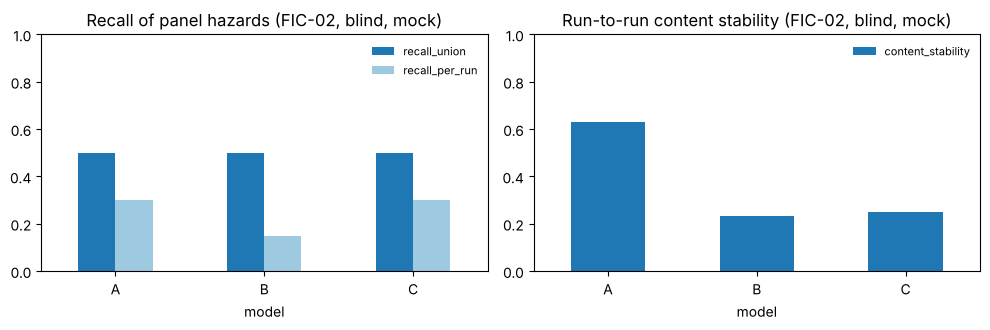

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col, title in [(axes[0], ["recall_union", "recall_per_run"], "Recall of panel hazards"),
                       (axes[1], ["content_stability"], "Run-to-run content stability")]:
    m[m["condition"] == "blind"].set_index("model")[col].plot.bar(ax=ax, rot=0, color=["#1f77b4", "#9ecae1"][:len(col)])
    ax.set(title=f"{title} (FIC-02, blind, mock)", ylim=(0, 1), xlabel="model")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

Inter-model agreement. On the union of runs it drifts towards 1 as repetitions accumulate
(each union tends to everything a model can say); per run it compares single consultations.

In [12]:
matching.agreement(evaluation, protocol.match_threshold)

,dossier,condition,pair,jaccard_union,jaccard_per_run
0,FIC-02,blind,A / B,1.0,0.420
1,FIC-02,blind,A / C,1.0,0.390
2,FIC-02,blind,B / C,1.0,0.278
3,FIC-02,challenger,A / B,1.0,0.498
4,FIC-02,challenger,A / C,1.0,0.445
5,FIC-02,challenger,B / C,1.0,0.409


## 6 · Blind adjudication workbook

Panel and model hazards are mixed, origin hidden, order shuffled with the frozen seed. Only the
Adjudication sheet is sent to the adjudicators; the key stays with the study lead until all
judgements are returned. Adjudicators should be peers who do not know the files.

In [13]:
full = WORK / "adjudication-aveugle.xlsx"
sent = WORK / "adjudication-a-transmettre.xlsx"
humans_full = {k: v.human_hazards for k, v in dossiers.items() if k != "FIC-01"}
n = adjudication.write_workbook(evaluation, humans_full, full, protocol.shuffle_seed)
adjudication.export_for_adjudicators(full, sent)
print(n, "lines to adjudicate")
pd.read_excel(sent, header=1).head(8)

13 lines to adjudicate


,Réf. aveugle,Dossier,Libellé du danger,Ce danger est-il valide ?,Est-il déjà couvert par un autre ?,Pertinence opérationnelle,Commentaire de l'adjudicateur
0,X-0001,FIC-02,Ergonomie de la nouvelle salle réduisant la co...,NaN,NaN,NaN,NaN
1,X-0002,FIC-02,Coupure radio pendant la bascule,NaN,NaN,NaN,NaN
2,X-0003,FIC-02,Bascule réalisée sans liste de vérification pa...,NaN,NaN,NaN,NaN
3,X-0004,FIC-02,Personnel technique indisponible la nuit de ba...,NaN,NaN,NaN,NaN
4,X-0005,FIC-02,Défaillance de la téléphonie de coordination c...,NaN,NaN,NaN,NaN
5,X-0006,FIC-02,Coupure des communications radio lors de la ba...,NaN,NaN,NaN,NaN
6,X-0007,FIC-02,Prévoir une répétition générale de la bascule,NaN,NaN,NaN,NaN
7,X-0008,FIC-02,Enregistrement des communications non opératio...,NaN,NaN,NaN,NaN
